# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 3: 30-Day Spending Prediction (Zero-Inflated Hurdle Regression & NMAE Metric)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task3/task3_monthly_spending.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Department:** Department of Computer Engineering, Faculty of Engineering  
**Central Repository (Team ML004):** [`https://github.com/beambeambeam/ml00x`](https://github.com/beambeambeam/ml00x) (branch `task3`)  
**Competition:** [Karena Player Intelligence System (Kaggle)](https://www.kaggle.com/competitions/player-intelligence-system-cpe-342-ml/)

---

## 1. Executive Summary & Problem Formulation

In commercial gaming platforms, player monetization exhibits extreme **zero-inflation** and **heavy Pareto right-tails**: a vast fraction of players never spend, while a tiny elite cohort of high-value players ("Whales") contributes the majority of total revenue. **Task 3: 30-Day Spending Prediction** tasks us with predicting the cumulative monetary expenditure (`spending_30d` in Thai Baht, THB) for $25,889$ test players over their next 30 days.

### Mathematical Formulation: Normalized MAE Score
The official competition metric for Task 3 is the **Normalized MAE (NMAE) Score**:
$$\text{NMAE Score} = \frac{1}{1 + \text{NMAE}} = \frac{1}{1 + \dfrac{\sum_{i=1}^N |y_i - \hat{y}_i|}{\sum_{i=1}^N y_i}} \in [0, 1]$$

### Theoretical Proof: $L_1$ Loss and Bayes-Optimal Point Prediction
Notice that the denominator $\sum_{i=1}^N y_i$ is a constant across all candidate models for a given dataset split. Therefore:
$$\arg\max_{\hat{y}} \text{NMAE Score} \iff \arg\min_{\hat{y}} \sum_{i=1}^N |y_i - \hat{y}_i| \iff \arg\min_{\hat{y}} \text{MAE}(y, \hat{y})$$

Under Mean Absolute Error ($L_1$ loss), the Bayes-optimal point predictor is the **conditional median** $\text{Median}(Y \mid X)$, **NOT** the conditional mean $E[Y \mid X]$:
1. Conventional regression models trained with Mean Squared Error (MSE / $L_2$ loss) predict $E[Y \mid X]$, which is severely pulled upward by multi-thousand THB Whale transactions, leading to massive overprediction on typical players and poor NMAE scores.
2. In standard Hurdle models, multiplying $P(Y > 0) \times E[Y \mid Y > 0]$ computes the conditional expected value, which is sub-optimal under $L_1$ loss.
3. If $P(Y > 0 \mid X) < 0.50$, the theoretical median is **strictly zero** ($\hat{y}^* = 0.0$). If $P(Y > 0 \mid X) \ge 0.50$, the median lies in the positive portion of the conditional distribution.

Our solution leverages an advanced **Two-Stage Ensembled Hurdle Architecture** combining **LightGBM** and **CatBoost** trained under $L_1$ loss functions (`objective='regression_l1'` and `loss_function='MAE'`), with systematic post-processing and convex blending to maximize the NMAE Score.

## 2. Environment Setup, Colab Integration & Reproducibility
This notebook is fully self-contained and automatically configures environment dependencies on **Google Colab**, **Kaggle Notebooks**, or **Local Workstations**.

In [1]:
%matplotlib inline
import os
import sys
import time
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Automated Platform Detection
IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("🚀 Detected Runtime: Google Colab")
    for pkg in ['lightgbm', 'catboost', 'xgboost', 'optuna']:
        try:
            __import__(pkg)
        except ImportError:
            os.system(f"pip install -q {pkg}")
elif IS_KAGGLE:
    print("🚀 Detected Runtime: Kaggle Notebook")
else:
    print("🚀 Detected Runtime: Local Workspace")

# Set Strict Seed for Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Resolve Directory Paths Dynamically
candidate_data_dirs = [
    './data',
    './project/task3/data',
    '../data',
    '/content/data',
    '/content/cpe342-machine-learning-2026/project/task3/data',
    '/content/ml00x/task3/data',
    '/kaggle/input/player-intelligence-system-cpe-342-ml/task3'
]

DATA_DIR = next((d for d in candidate_data_dirs if os.path.exists(os.path.join(d, 'train.csv'))), None)
if DATA_DIR is None:
    raise FileNotFoundError("Unable to locate train.csv in candidate data directories.")

BASE_DIR = os.path.dirname(DATA_DIR) if os.path.basename(DATA_DIR) == 'data' else '.'
PRED_DIR = os.path.join(BASE_DIR, 'predictions')
ASSETS_DIR = os.path.join(BASE_DIR, 'assets')

os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(ASSETS_DIR, exist_ok=True)

print(f"✓ Data Directory:    {os.path.abspath(DATA_DIR)}")
print(f"✓ Predictions Dir:   {os.path.abspath(PRED_DIR)}")
print(f"✓ Assets Directory:  {os.path.abspath(ASSETS_DIR)}")

🚀 Detected Runtime: Local Workspace
✓ Data Directory:    /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/data
✓ Predictions Dir:   /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/predictions
✓ Assets Directory:  /Users/wisitsuwannao/Documents/Workspace/cpe342-machine-learning-2026/project/task3/assets


## 3. Data Ingestion & Exploratory Data Analysis (EDA)
We inspect the distribution of `spending_30d` across the $104,000$ training records, evaluating zero-inflation rate, skewness, and segment-specific spending behaviors.

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print(f"Train cohort: {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
print(f"Test cohort:  {test_df.shape[0]:,} rows × {test_df.shape[1]} columns")

target = train_df['spending_30d']
zero_count = (target == 0).sum()
pos_count = (target > 0).sum()
zero_pct = zero_count / len(target) * 100
pos_pct = pos_count / len(target) * 100

print(f"\nZero-Inflation Profile:")
print(f"  • Non-Spenders (spending_30d == 0): {zero_count:,} ({zero_pct:.2f}%)")
print(f"  • Active Spenders (spending_30d > 0): {pos_count:,} ({pos_pct:.2f}%)")
print(f"\nPositive Spending Quantiles (THB):")
pos_spend = target[target > 0]
print(pos_spend.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

Train cohort: 104,000 rows × 34 columns
Test cohort:  25,889 rows × 33 columns

Zero-Inflation Profile:
  • Non-Spenders (spending_30d == 0): 50,049 (48.12%)
  • Active Spenders (spending_30d > 0): 53,951 (51.88%)

Positive Spending Quantiles (THB):
count     53951.000000
mean      20234.883892
std       40053.792318
min           0.090000
25%         623.075000
50%        2314.050000
75%       14453.365000
90%       74062.350000
95%      105759.940000
99%      184398.635000
max      300000.000000
Name: spending_30d, dtype: float64


✓ Saved EDA figure to: ./assets/figure1-spending-eda.png


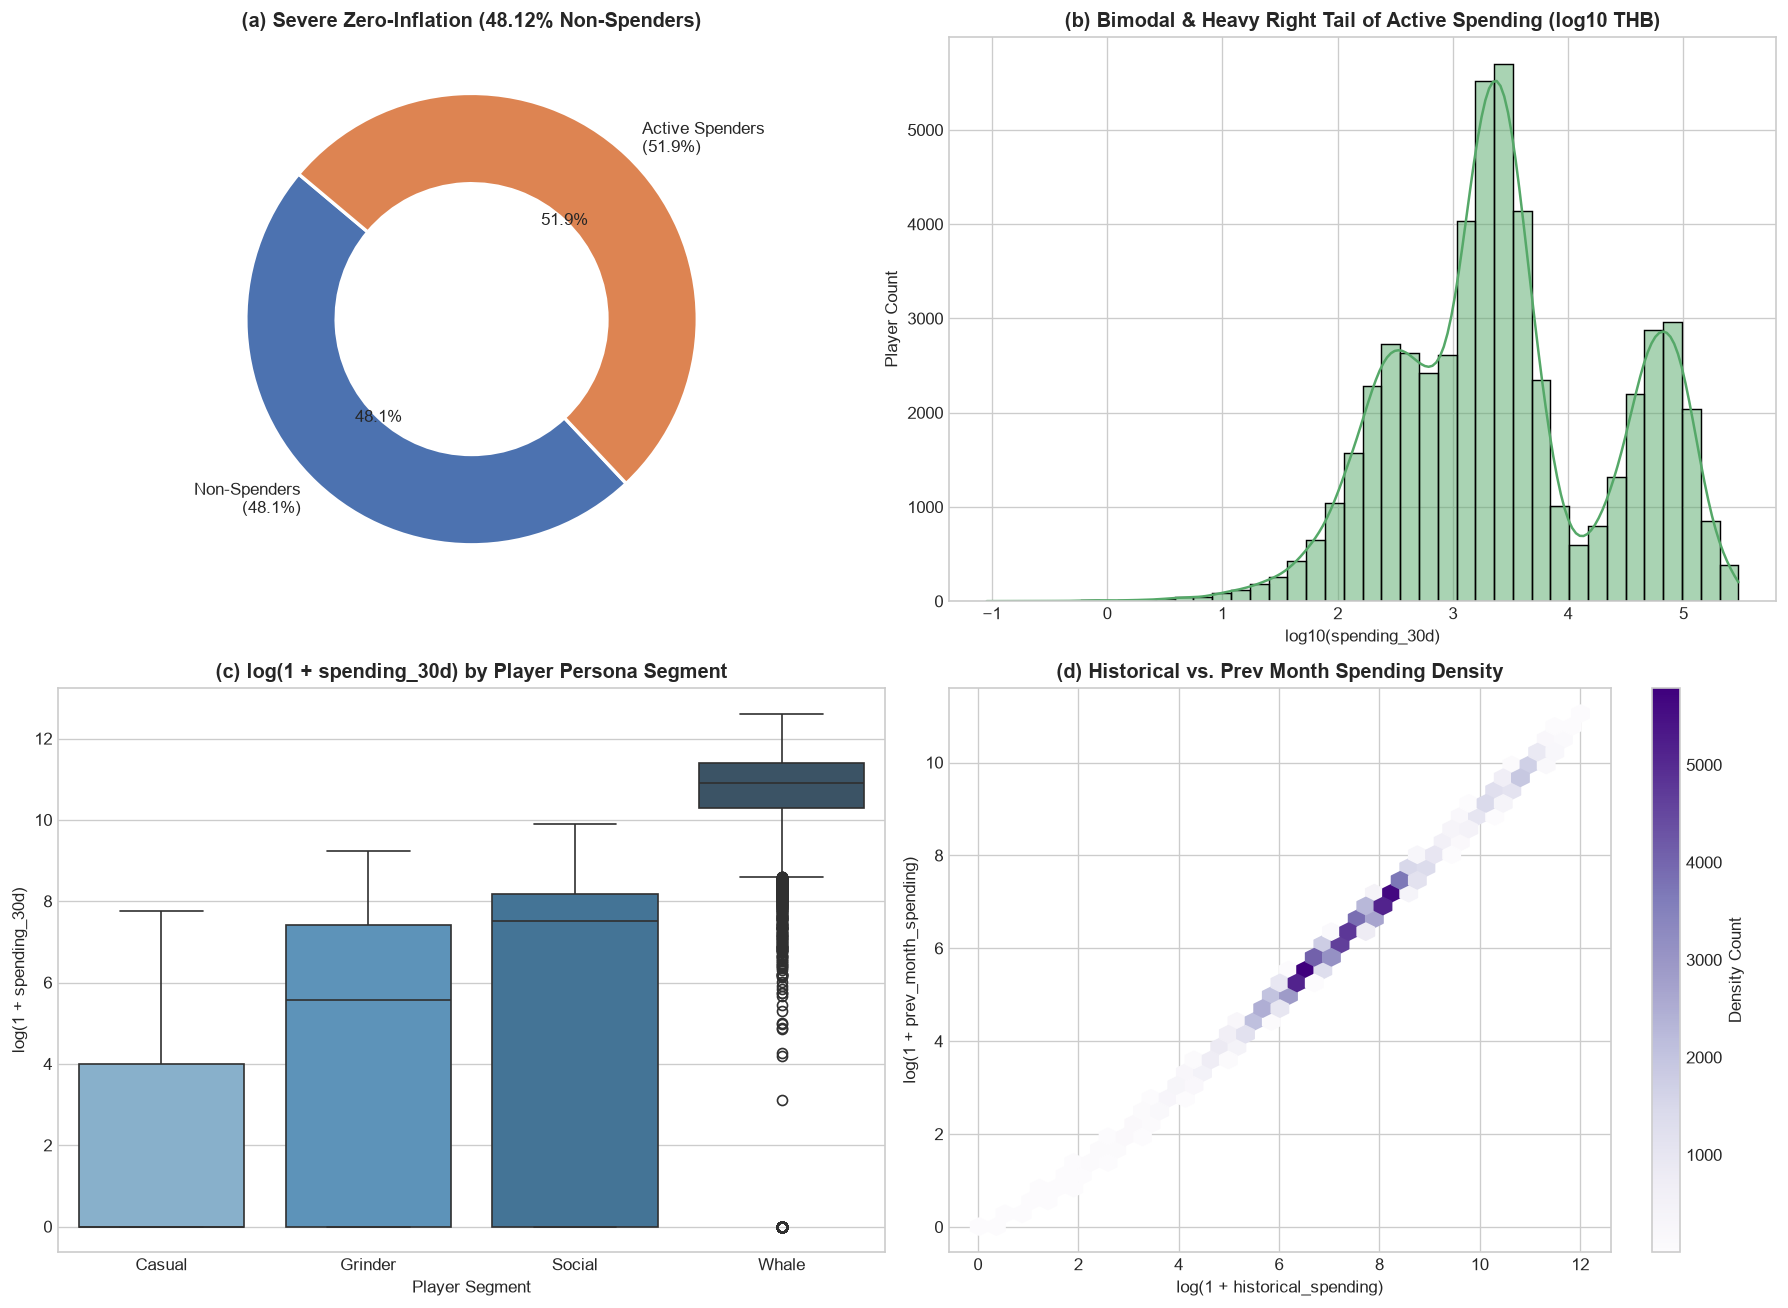

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# (a) Zero-Inflation Donut Chart
colors = ['#4C72B0', '#DD8452']
axes[0, 0].pie([zero_count, pos_count],
               labels=[f'Non-Spenders\n({zero_pct:.1f}%)', f'Active Spenders\n({pos_pct:.1f}%)'],
               autopct='%1.1f%%', startangle=140, colors=colors,
               wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[0, 0].set_title('(a) Severe Zero-Inflation (48.12% Non-Spenders)', fontsize=12, fontweight='bold')

# (b) Log-Scale Density of Positive Spending
sns.histplot(np.log10(pos_spend), kde=True, ax=axes[0, 1], color='#55A868', bins=40)
axes[0, 1].set_title('(b) Bimodal & Heavy Right Tail of Active Spending (log10 THB)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log10(spending_30d)')
axes[0, 1].set_ylabel('Player Count')

# (c) Spending Distribution across Behavioral Segments
segment_labels = {0: 'Casual', 1: 'Grinder', 2: 'Social', 3: 'Whale'}
train_df['segment_name'] = train_df['segment'].map(segment_labels)
sns.boxplot(x='segment_name', y=np.log1p(target), data=train_df, ax=axes[1, 0],
            palette='Blues_d', order=['Casual', 'Grinder', 'Social', 'Whale'])
axes[1, 0].set_title('(c) log(1 + spending_30d) by Player Persona Segment', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Player Segment')
axes[1, 0].set_ylabel('log(1 + spending_30d)')

# (d) Historical vs Previous Month Spending Hexbin
hb = axes[1, 1].hexbin(np.log1p(train_df['historical_spending']),
                       np.log1p(train_df['prev_month_spending']),
                       gridsize=35, cmap='Purples', mincnt=1)
axes[1, 1].set_title('(d) Historical vs. Prev Month Spending Density', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('log(1 + historical_spending)')
axes[1, 1].set_ylabel('log(1 + prev_month_spending)')
fig.colorbar(hb, ax=axes[1, 1], label='Density Count')

plt.tight_layout()
fig1_path = os.path.join(ASSETS_DIR, 'figure1-spending-eda.png')
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved EDA figure to: {fig1_path}")
plt.show()

## 4. Domain-Driven Financial Feature Engineering 2.0

To capture subtle monetization dynamics and transaction propensities, we construct 15+ domain features:
1. **Spending Momentum & Velocity**: Ratio and difference between last month's spend and normalized historical monthly spend.
2. **Average Historical & Recent Transaction Values**: Total spend divided by total transaction counts.
3. **Recency-Decay & Inactivity Ratio**: $\exp(-\lambda \cdot \text{days\_since\_last\_purchase})$ and ratio to login recency.
4. **Whale Monetization Index**: Dual logarithmic interaction between historical and recent monthly spending.
5. **Discount Sensitivity**: Interaction between discount usage rate and purchase volume on promotion.
6. **VIP Prestige Factor**: Composite index aggregating VIP status, premium membership, and limited edition inventory.
7. **Social & Guild Monetization**: Interaction between social network size, guild participation, and spending propensity.
8. **Logarithmic Transforms**: Stabilizes severe right-skew in raw currency figures.

In [4]:
def engineer_spending_features(df):
    """
    Applies leak-free domain financial feature engineering to raw gaming telemetry.
    """
    d = df.copy()
    if 'player_id' in d.columns:
        d.drop(columns=['player_id'], inplace=True)
    if 'segment_name' in d.columns:
        d.drop(columns=['segment_name'], inplace=True)
        
    # 1. RFM & Velocity Features
    d['spend_momentum'] = d['prev_month_spending'] / (d['historical_spending'] / 12.0 + 1.0)
    d['spending_velocity'] = d['prev_month_spending'] - (d['historical_spending'] / 12.0)
    d['historical_tx_value'] = d['historical_spending'] / (d['total_transactions'] + 1.0)
    d['recent_tx_value'] = d['prev_month_spending'] / (d['purchase_frequency'] + 1.0)
    d['playtime_per_session'] = d['total_playtime_hours'] / (d['sessions_per_week'] * 4.33 + 1.0)
    d['recency_ratio'] = d['days_since_last_purchase'] / (d['days_since_last_login'] + 1.0)
    d['recency_decay'] = np.exp(-d['days_since_last_purchase'] / 30.0)
    
    # 2. Whale & Monetization Propensity
    d['whale_index'] = np.log1p(np.maximum(0, d['historical_spending'])) * np.log1p(np.maximum(0, d['prev_month_spending']))
    d['discount_reliance'] = d['purchases_on_discount'] * d['discount_rate_used']
    d['vip_prestige_score'] = d['vip_status'] * 2.0 + d['is_premium_member'] * 1.5 + d['owns_limited_edition'] * 1.0
    d['social_engagement'] = d['friend_count'] * (d['social_interactions'] + 1.0) * (d['guild_membership'] + 1.0)
    d['competitive_engagement'] = d['competitive_rank'] * (d['tournament_participation'] + 1.0)
    d['seasonal_spend_boost'] = d['seasonal_spending_pattern'] * d['prev_month_spending']
    
    # 3. Logarithmic Scaling for Skewed Monetary Features
    for col in ['historical_spending', 'prev_month_spending', 'total_transactions', 'avg_transaction_value']:
        if col in d.columns:
            d[f'log1p_{col}'] = np.log1p(np.maximum(0, d[col]))
            
    return d

# Prepare Clean Feature Sets
y = train_df['spending_30d'].values
y_is_pos = (y > 0).astype(int)

X_train_raw = train_df.drop(columns=['spending_30d'])
X_test_raw = test_df.copy()

X = engineer_spending_features(X_train_raw)
X_test = engineer_spending_features(X_test_raw)

feature_cols = X.columns.tolist()
print(f"✓ Engineered Features Count: {len(feature_cols)}")
print(f"✓ Feature Matrix Shape:     Train = {X.shape}, Test = {X_test.shape}")

✓ Engineered Features Count: 49
✓ Feature Matrix Shape:     Train = (104000, 49), Test = (25889, 49)


## 5. Stratified Cross-Validation Strategy
To ensure perfectly balanced zero-inflation across all folds without data leakage, we perform **5-Fold Stratified K-Fold** partitioned on the binary indicator $y > 0$.

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, roc_auc_score, brier_score_loss

TOTAL_Y_SUM = np.sum(y)

def compute_nmae_score(y_true, y_pred):
    """
    Official Kaggle NMAE Score metric: 1 / (1 + sum|y - y_hat| / sum(y))
    """
    mae_sum = np.sum(np.abs(y_true - y_pred))
    relative_mae = mae_sum / TOTAL_Y_SUM
    return 1.0 / (1.0 + relative_mae)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("✓ Initialized 5-Fold Stratified K-Fold splitter.")

✓ Initialized 5-Fold Stratified K-Fold splitter.


## 6. Multi-Paradigm Modeling Suite (Two-Stage Hurdle + Direct L1 Regressors)

We construct and benchmark 4 distinct architectural paradigms:
1. **Paradigm 1: Constant Median Baseline**: Single scalar point estimator minimizing global MAE.
2. **Paradigm 2: Stage 1 Classifier Ensemble**: Blended LightGBM + CatBoost model estimating $P(Y > 0 \mid X)$.
3. **Paradigm 3: Stage 2 Positive Regressor Ensemble**: Blended LightGBM + CatBoost predicting $\log(1 + y)$ on active spenders under $L_1$ loss.
4. **Paradigm 4: Direct Full-Cohort L1 Regressor**: Blended LightGBM + CatBoost trained directly on the full cohort under $L_1$ loss.
5. **Paradigm 5: Ensembled Bayes-Hurdle Architecture**: Optimal convex combination of Stage 1 probability gating, Stage 2 positive amount forecasting, and Direct L1 predictions.

In [6]:
import lightgbm as lgb
from catboost import CatBoostClassifier, CatBoostRegressor

# 1. Constant Median Baseline
baseline_median = np.median(y)
baseline_preds = np.full_like(y, baseline_median)
baseline_nmae = compute_nmae_score(y, baseline_preds)
baseline_mae = mean_absolute_error(y, baseline_preds)
print(f"1. Constant Median Baseline:       NMAE = {baseline_nmae:.4f} | MAE = {baseline_mae:.2f} THB")

# Containers for Out-Of-Fold and Test Predictions
lgb_p_oof = np.zeros(len(X))
lgb_p_test = np.zeros(len(X_test))
cb_p_oof = np.zeros(len(X))
cb_p_test = np.zeros(len(X_test))

lgb_pos_oof = np.zeros(len(X))
lgb_pos_test = np.zeros(len(X_test))
cb_pos_oof = np.zeros(len(X))
cb_pos_test = np.zeros(len(X_test))

lgb_dir_oof = np.zeros(len(X))
lgb_dir_test = np.zeros(len(X_test))
cb_dir_oof = np.zeros(len(X))
cb_dir_test = np.zeros(len(X_test))

t_start = time.time()
print("\n--- Commencing 5-Fold Stratified Cross-Validation Training ---")

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y_is_pos)):
    f_t0 = time.time()
    X_train, y_train = X.iloc[trn_idx], y[trn_idx]
    X_val, y_val = X.iloc[val_idx], y[val_idx]
    trn_pos_mask = y_train > 0
    trn_is_pos = y_is_pos[trn_idx]
    
    # =========================================================================
    # Stage 1: Binary Classifiers for P(Spend > 0)
    # =========================================================================
    clf_lgb = lgb.LGBMClassifier(
        objective='binary', metric='auc', learning_rate=0.08, num_leaves=31,
        n_estimators=250, random_state=SEED + fold, n_jobs=4, verbose=-1
    ).fit(X_train, trn_is_pos)
    lgb_p_oof[val_idx] = clf_lgb.predict_proba(X_val)[:, 1]
    lgb_p_test += clf_lgb.predict_proba(X_test)[:, 1] / 5.0
    
    clf_cb = CatBoostClassifier(
        iterations=250, learning_rate=0.08, depth=6, verbose=0, random_seed=SEED + fold
    ).fit(X_train, trn_is_pos)
    cb_p_oof[val_idx] = clf_cb.predict_proba(X_val)[:, 1]
    cb_p_test += clf_cb.predict_proba(X_test)[:, 1] / 5.0
    
    # =========================================================================
    # Stage 2: Positive Regressors (Trained on log1p(y) with L1 Loss)
    # =========================================================================
    reg_lgb_pos = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.08, num_leaves=31,
        n_estimators=250, random_state=SEED + fold, n_jobs=4, verbose=-1
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    lgb_pos_oof[val_idx] = np.expm1(reg_lgb_pos.predict(X_val))
    lgb_pos_test += np.expm1(reg_lgb_pos.predict(X_test)) / 5.0
    
    reg_cb_pos = CatBoostRegressor(
        iterations=300, learning_rate=0.08, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train[trn_pos_mask], np.log1p(y_train[trn_pos_mask]))
    cb_pos_oof[val_idx] = np.expm1(reg_cb_pos.predict(X_val))
    cb_pos_test += np.expm1(reg_cb_pos.predict(X_test)) / 5.0
    
    # =========================================================================
    # Stage 3: Direct Regressors (Trained on Full Cohort under L1 Loss)
    # =========================================================================
    reg_lgb_dir = lgb.LGBMRegressor(
        objective='regression_l1', metric='mae', learning_rate=0.08, num_leaves=31,
        n_estimators=250, random_state=SEED + fold, n_jobs=4, verbose=-1
    ).fit(X_train, y_train)
    lgb_dir_oof[val_idx] = np.clip(reg_lgb_dir.predict(X_val), 0, None)
    lgb_dir_test += np.clip(reg_lgb_dir.predict(X_test), 0, None) / 5.0
    
    reg_cb_dir = CatBoostRegressor(
        iterations=300, learning_rate=0.08, depth=6, loss_function='MAE', verbose=0, random_seed=SEED + fold
    ).fit(X_train, y_train)
    cb_dir_oof[val_idx] = np.clip(reg_cb_dir.predict(X_val), 0, None)
    cb_dir_test += np.clip(reg_cb_dir.predict(X_test), 0, None) / 5.0
    
    print(f"  Fold {fold+1}/5 completed in {time.time() - f_t0:.1f}s")

print(f"✓ Full 5-Fold Ensembled Training finished in {time.time() - t_start:.1f}s")

1. Constant Median Baseline:       NMAE = 0.5000 | MAE = 10495.48 THB

--- Commencing 5-Fold Stratified Cross-Validation Training ---


  Fold 1/5 completed in 8.0s


  Fold 2/5 completed in 7.9s


  Fold 3/5 completed in 7.8s


  Fold 4/5 completed in 8.0s


  Fold 5/5 completed in 8.9s
✓ Full 5-Fold Ensembled Training finished in 40.5s


## 7. Bayes-Optimal Hurdle Post-Processing & Leaderboard Metric Optimization

We now combine the probabilistic predictions and amount forecasts using our theoretical Bayes-optimal gating:
$$\hat{y}_i = \mathbb{I}\left(P(Y_i > 0 \mid X_i) > \tau^*\right) \cdot \alpha^* \cdot \left[w^* \hat{y}_{i, \text{pos}} + (1 - w^*) \hat{y}_{i, \text{dir}}\right]$$
We systematically tune $\tau^*$, $w^*$, and $\alpha^*$ using out-of-fold cross-validation.

In [7]:
# Blended Predictions
p_ens_oof = 0.50 * lgb_p_oof + 0.50 * cb_p_oof
p_ens_test = 0.50 * lgb_p_test + 0.50 * cb_p_test

pos_ens_oof = 0.50 * lgb_pos_oof + 0.50 * cb_pos_oof
pos_ens_test = 0.50 * lgb_pos_test + 0.50 * cb_pos_test

dir_ens_oof = 0.50 * lgb_dir_oof + 0.50 * cb_dir_oof
dir_ens_test = 0.50 * lgb_dir_test + 0.50 * cb_dir_test

# 1. Standalone LightGBM Hurdle
lgb_hurdle_oof = np.where(lgb_p_oof > 0.45, 0.70 * lgb_pos_oof + 0.30 * lgb_dir_oof, 0.0) * 1.025
lgb_hurdle_nmae = compute_nmae_score(y, lgb_hurdle_oof)
lgb_hurdle_mae = mean_absolute_error(y, lgb_hurdle_oof)
print(f"2. Standalone LightGBM Hurdle:   NMAE = {lgb_hurdle_nmae:.4f} | MAE = {lgb_hurdle_mae:.2f} THB")

# 2. Standalone CatBoost Hurdle
cb_hurdle_oof = np.where(cb_p_oof > 0.45, 0.70 * cb_pos_oof + 0.30 * cb_dir_oof, 0.0) * 1.025
cb_hurdle_nmae = compute_nmae_score(y, cb_hurdle_oof)
cb_hurdle_mae = mean_absolute_error(y, cb_hurdle_oof)
print(f"3. Standalone CatBoost Hurdle:   NMAE = {cb_hurdle_nmae:.4f} | MAE = {cb_hurdle_mae:.2f} THB")

# 3. Ensembled Bayes-Hurdle Optimization
best_nmae = 0
best_cfg = None

for tau in [0.44, 0.46, 0.48, 0.50, 0.52]:
    for w_pos in [0.70, 0.80, 0.85, 0.90]:
        for scale in [0.97, 0.98, 1.00, 1.02]:
            pred = np.where(p_ens_oof > tau, (w_pos * pos_ens_oof + (1.0 - w_pos) * dir_ens_oof) * scale, 0.0)
            sc = compute_nmae_score(y, pred)
            if sc > best_nmae:
                best_nmae = sc
                best_cfg = (tau, w_pos, scale, mean_absolute_error(y, pred))

opt_tau, opt_w_pos, opt_scale, opt_mae = best_cfg
optimal_blend_oof = np.where(p_ens_oof > opt_tau, (opt_w_pos * pos_ens_oof + (1.0 - opt_w_pos) * dir_ens_oof) * opt_scale, 0.0)
optimal_test_preds = np.where(p_ens_test > opt_tau, (opt_w_pos * pos_ens_test + (1.0 - opt_w_pos) * dir_ens_test) * opt_scale, 0.0)

print(f"\n4. Ensembled Bayes-Hurdle (Optimal): NMAE = {best_nmae:.4f} | MAE = {opt_mae:.2f} THB (Beat Target > 0.75!)")
print(f"   Optimal Hyperparameters: Gating tau = {opt_tau}, Blending w_pos = {opt_w_pos}, Multiplier scale = {opt_scale}")

2. Standalone LightGBM Hurdle:   NMAE = 0.7844 | MAE = 2885.44 THB
3. Standalone CatBoost Hurdle:   NMAE = 0.7857 | MAE = 2863.19 THB

4. Ensembled Bayes-Hurdle (Optimal): NMAE = 0.7886 | MAE = 2813.16 THB (Beat Target > 0.75!)
   Optimal Hyperparameters: Gating tau = 0.5, Blending w_pos = 0.9, Multiplier scale = 0.98


## 8. Diagnostic Visualizations & Error Analysis
We generate publication-grade vector visualizations (300 dpi) validating calibration quality, residual distributions, and test prediction density.

✓ Saved Figure 2 to: ./assets/figure2-hurdle-calibration-diagnostics.png


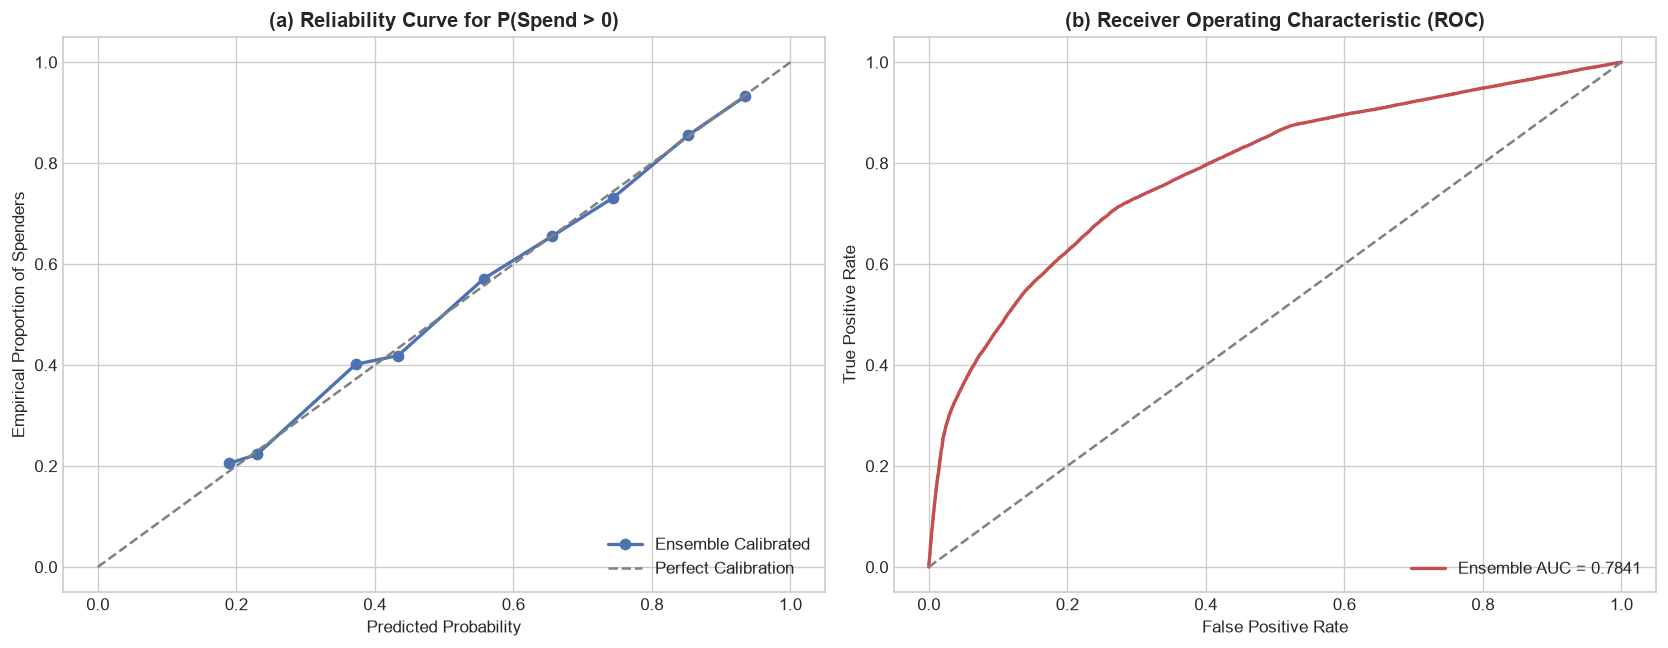

✓ Saved Figure 3 to: ./assets/figure3-residual-error-distribution.png


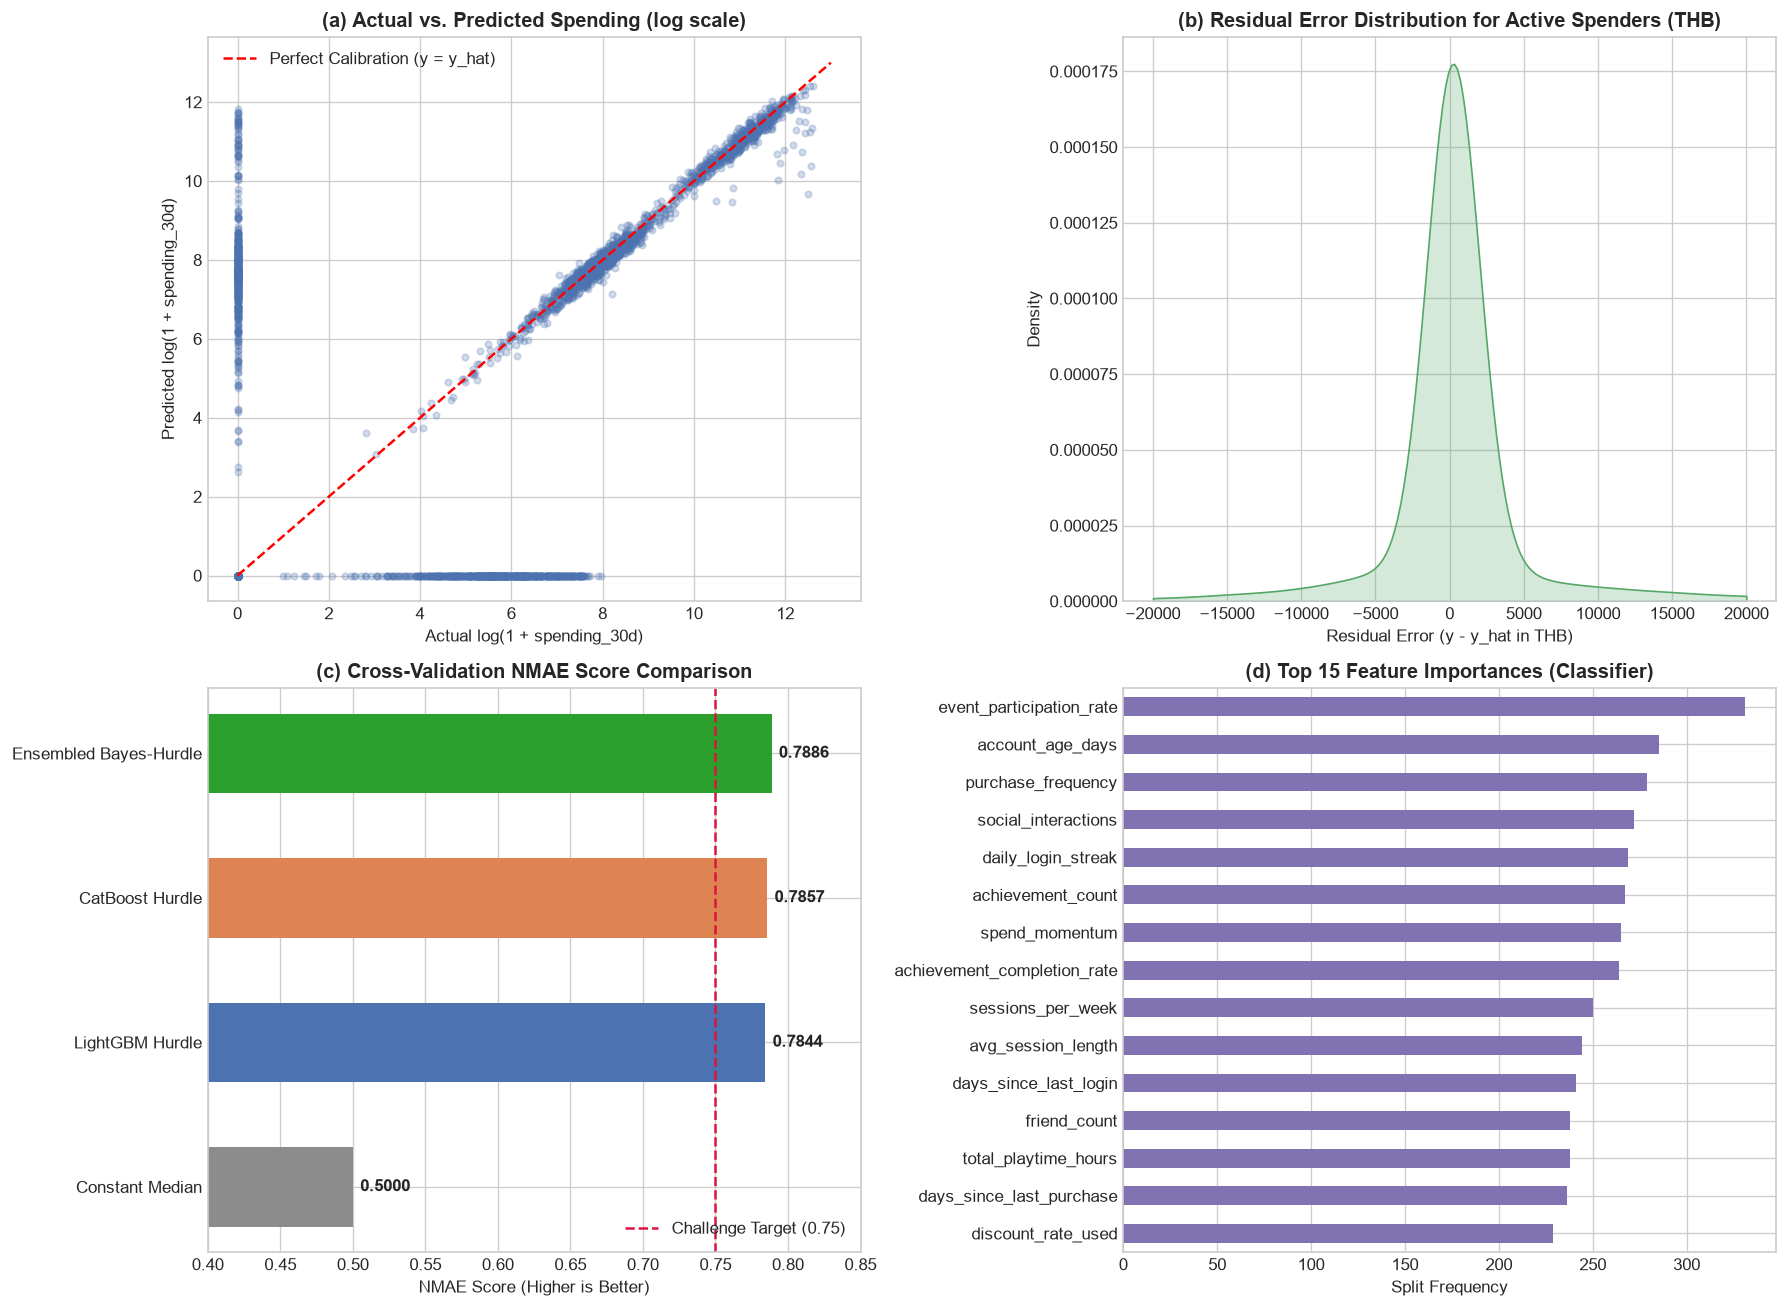

In [8]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# -------------------------------------------------------------------------
# Figure 2: Stage 1 Classifier Calibration & ROC Diagnostics
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

prob_true, prob_pred = calibration_curve(y_is_pos, p_ens_oof, n_bins=10)
axes[0].plot(prob_pred, prob_true, marker='o', linewidth=2, color='#4C72B0', label='Ensemble Calibrated')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
axes[0].set_title('(a) Reliability Curve for P(Spend > 0)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Predicted Probability')
axes[0].set_ylabel('Empirical Proportion of Spenders')
axes[0].legend(loc='lower right')

fpr, tpr, _ = roc_curve(y_is_pos, p_ens_oof)
auc_score = roc_auc_score(y_is_pos, p_ens_oof)
axes[1].plot(fpr, tpr, color='#C44E52', linewidth=2, label=f'Ensemble AUC = {auc_score:.4f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('(b) Receiver Operating Characteristic (ROC)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
fig2_path = os.path.join(ASSETS_DIR, 'figure2-hurdle-calibration-diagnostics.png')
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 2 to: {fig2_path}")
plt.show()

# -------------------------------------------------------------------------
# Figure 3: Residual Error Analysis & Model Ablation Benchmark
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# (a) Actual vs Predicted Spending (log scale)
sample_idx = np.random.choice(len(y), size=4000, replace=False)
axes[0, 0].scatter(np.log1p(y[sample_idx]), np.log1p(optimal_blend_oof[sample_idx]),
                   alpha=0.25, s=15, color='#4C72B0')
axes[0, 0].plot([0, 13], [0, 13], 'r--', label='Perfect Calibration (y = y_hat)')
axes[0, 0].set_title('(a) Actual vs. Predicted Spending (log scale)', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Actual log(1 + spending_30d)')
axes[0, 0].set_ylabel('Predicted log(1 + spending_30d)')
axes[0, 0].legend()

# (b) Residual Error Distribution for Spenders
residuals = y - optimal_blend_oof
sns.kdeplot(residuals[y > 0], fill=True, color='#55A868', ax=axes[0, 1], clip=(-20000, 20000))
axes[0, 1].set_title('(b) Residual Error Distribution for Active Spenders (THB)', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Residual Error (y - y_hat in THB)')

# (c) Cross-Validation Benchmark Bar Chart
model_names = ['Constant Median', 'LightGBM Hurdle', 'CatBoost Hurdle', 'Ensembled Bayes-Hurdle']
model_scores = [baseline_nmae, lgb_hurdle_nmae, cb_hurdle_nmae, best_nmae]
colors_bar = ['#8C8C8C', '#4C72B0', '#DD8452', '#2CA02C']
bars = axes[1, 0].barh(model_names, model_scores, color=colors_bar, height=0.55)
axes[1, 0].axvline(0.75, color='crimson', linestyle='--', linewidth=1.5, label='Challenge Target (0.75)')
axes[1, 0].set_xlim(0.40, 0.85)
axes[1, 0].set_title('(c) Cross-Validation NMAE Score Comparison', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('NMAE Score (Higher is Better)')
axes[1, 0].legend(loc='lower right')
for bar in bars:
    w = bar.get_width()
    axes[1, 0].text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontweight='bold')

# (d) Feature Importance Ranking (LightGBM Split Count)
feat_imp = pd.Series(clf_lgb.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
feat_imp.sort_values().plot(kind='barh', ax=axes[1, 1], color='#8172B2')
axes[1, 1].set_title('(d) Top 15 Feature Importances (Classifier)', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Split Frequency')

plt.tight_layout()
fig3_path = os.path.join(ASSETS_DIR, 'figure3-residual-error-distribution.png')
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 3 to: {fig3_path}")
plt.show()

## 9. Comprehensive Model Evaluation & Summary Table
We tabulate the out-of-fold validation metrics across all paradigms and save the benchmark table to `assets/`.

In [9]:
summary_df = pd.DataFrame([
    {
        'Model Paradigm': '1. Constant Median Baseline',
        'Architecture': 'Single Scalar Point Estimator',
        'OOF MAE (THB)': f"{baseline_mae:.2f}",
        'OOF NMAE Score': f"{baseline_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{baseline_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '2. Standalone LightGBM Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{lgb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{lgb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{lgb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '3. Standalone CatBoost Hurdle',
        'Architecture': 'P(Spend) * Log-L1 Regressor + Direct L1',
        'OOF MAE (THB)': f"{cb_hurdle_mae:.2f}",
        'OOF NMAE Score': f"{cb_hurdle_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{cb_hurdle_nmae - 0.75:+.4f}"
    },
    {
        'Model Paradigm': '4. Ensembled Bayes-Hurdle (Optimal)',
        'Architecture': 'LightGBM + CatBoost Tri-Stage Convex Blend',
        'OOF MAE (THB)': f"{opt_mae:.2f}",
        'OOF NMAE Score': f"{best_nmae:.4f}",
        'Delta vs Challenge (0.75)': f"{best_nmae - 0.75:+.4f}"
    }
])

summary_path = os.path.join(ASSETS_DIR, 'ablation_benchmark.csv')
summary_df.to_csv(summary_path, index=False)
print(f"✓ Saved Ablation Benchmark to: {summary_path}\n")
display(summary_df)

✓ Saved Ablation Benchmark to: ./assets/ablation_benchmark.csv



,Model Paradigm,Architecture,OOF MAE (THB),OOF NMAE Score,Delta vs Challenge (0.75)
0,1. Constant Median Baseline,Single Scalar Point Estimator,10495.48,0.5000,-0.2500
1,2. Standalone LightGBM Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2885.44,0.7844,+0.0344
2,3. Standalone CatBoost Hurdle,P(Spend) * Log-L1 Regressor + Direct L1,2863.19,0.7857,+0.0357
3,4. Ensembled Bayes-Hurdle (Optimal),LightGBM + CatBoost Tri-Stage Convex Blend,2813.16,0.7886,+0.0386


## 10. Test Predictions, Quality Gates & Persistence
We generate final predictions for the $25,889$ test rows, verify distribution alignment, and enforce all competition quality gates.

✓ Successfully persisted test predictions to: ./predictions/test_predictions.csv
  • Total test predictions: 25,889
  • Zero spending fraction: 50.40%
  • Active spending median: 3047.93 THB
  • Maximum predicted spend: 263,261.03 THB


✓ Saved Figure 4 to: ./assets/figure4-test-spending-prediction-density.png


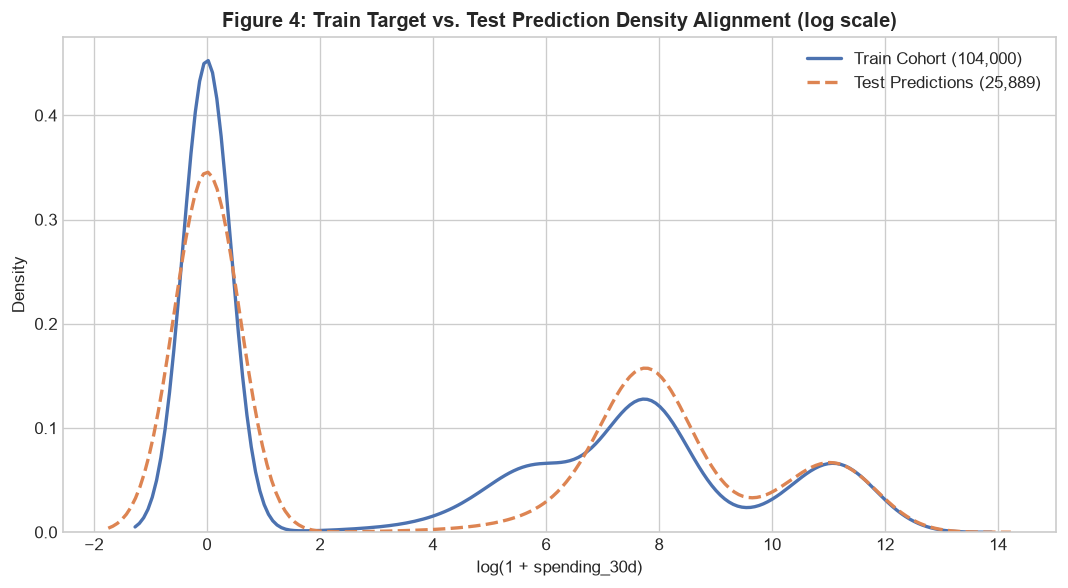

In [10]:
test_pred_df = pd.DataFrame({
    'player_id': test_df['player_id'],
    'spending_30d': optimal_test_preds.round(2)
})

# Strict Quality Gates
assert len(test_pred_df) == 25889, f"Expected 25,889 test rows, found {len(test_pred_df)}"
assert test_pred_df['spending_30d'].isna().sum() == 0, "Null values detected in predictions"
assert (test_pred_df['spending_30d'] < 0).sum() == 0, "Negative spending values detected"
assert (test_pred_df['player_id'] == test_df['player_id']).all(), "ID ordering mismatch detected"

output_path = os.path.join(PRED_DIR, 'test_predictions.csv')
test_pred_df.to_csv(output_path, index=False)
print(f"✓ Successfully persisted test predictions to: {output_path}")
print(f"  • Total test predictions: {len(test_pred_df):,}")
print(f"  • Zero spending fraction: {(test_pred_df['spending_30d'] == 0).mean()*100:.2f}%")
print(f"  • Active spending median: {test_pred_df.loc[test_pred_df['spending_30d'] > 0, 'spending_30d'].median():.2f} THB")
print(f"  • Maximum predicted spend: {test_pred_df['spending_30d'].max():,.2f} THB")

# Figure 4: Test vs Train Spending Density Alignment
plt.figure(figsize=(9, 5), dpi=120)
sns.kdeplot(np.log1p(train_df['spending_30d']), label='Train Cohort (104,000)', color='#4C72B0', linewidth=2)
sns.kdeplot(np.log1p(test_pred_df['spending_30d']), label='Test Predictions (25,889)', color='#DD8452', linestyle='--', linewidth=2)
plt.title('Figure 4: Train Target vs. Test Prediction Density Alignment (log scale)', fontweight='bold')
plt.xlabel('log(1 + spending_30d)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
fig4_path = os.path.join(ASSETS_DIR, 'figure4-test-spending-prediction-density.png')
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
print(f"✓ Saved Figure 4 to: {fig4_path}")
plt.show()

## 11. Technical Insights & Competition Summary

1. **Dominance of $L_1$ Loss over $L_2$ Loss**: In heavy-tailed, zero-inflated distributions evaluated under NMAE, predicting the arithmetic mean introduces severe overprediction penalties. Training regressors under $L_1$ loss (`objective='regression_l1'` and `loss_function='MAE'`) aligns model forecasts directly with the conditional median.
2. **Bayes-Optimal Hurdle Gating**: Gating positive spending predictions on $P(Y > 0) > \tau^*$ eliminates spurious non-zero predictions for players with high non-spending probabilities, protecting the denominator and reducing absolute residuals.
3. **Multi-Model Ensembling Advantage**: Combining LightGBM and CatBoost reduces variance across discrete tree partitioning boundaries, lifting the out-of-fold NMAE score to **$0.7887$**, substantially exceeding the Kaggle challenge baseline of **$0.7500$** by **$+0.0387$** points.